# FD001–FD004: khi nào một thay đổi được xem là cải thiện?

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Notebook 03 cho kết quả baseline FD001. Hai câu hỏi tiếp theo là: mô hình đó dùng sang subset khác
được không, và thay cấu hình có cải thiện đủ để thay baseline không?

Notebook tính lại metric, bootstrap và so sánh cặp từ **dự đoán của các thí nghiệm đã hoàn tất**.
Theo dõi động cơ train 1 trong phép so sánh baseline–candidate để thấy một trường hợp cải thiện
chưa quyết định được kết quả chung.

Phần huấn luyện nhiều cấu hình của nested cross-validation không được chạy lại ở đây.
Kết quả tính lại nằm trong `outputs/notebook05/run-*/`; các thí nghiệm gốc được giữ nguyên.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from cmapss.presentation import COLORS, apply_plot_style, style_figure
apply_plot_style()


In [2]:
import tempfile

output_root = ROOT / "outputs/notebook05"
output_root.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
(OUTPUT / "figures").mkdir()
CROSS = ROOT / "outputs/cross_dataset"
matrix = json.loads((CROSS / "matrix.json").read_text(encoding="utf-8"))
assert matrix["window_cycles"] == 10

## 1. Học và đánh giá cùng subset khác với transfer thế nào?

`within_subset` học từ train và dự đoán test của cùng subset. `transfer` dùng mô hình học từ FD001
để dự đoán test FD002–FD004, không fit lại trên subset đích. ID động cơ chỉ có nghĩa trong từng subset.

Thí nghiệm này dùng window **10 cycle**, vì động cơ test ngắn nhất của FD004 chỉ dài 19 cycle.
Do đó, MAE FD001 trong phần này không so trực tiếp với baseline window 30 ở notebook 03.

Đọc dự đoán đã lưu, tính lại MAE/RMSE và CI bootstrap 95% theo động cơ, rồi đối chiếu `matrix.json`.

In [3]:
from cmapss.modeling.metrics import summarize_prediction_errors, bootstrap_metric_intervals

rows = []
for item in matrix["evaluations"]:
    source, target = item["source_dataset"], item["target_dataset"]
    path = CROSS / f"evaluations/{source}_to_{target}/modeling/predictions/final_evaluation.parquet"
    evaluation = pd.read_parquet(path)
    scores = summarize_prediction_errors(evaluation)
    interval = bootstrap_metric_intervals(evaluation, n_resamples=10000, seed=42)["mean_engine_mae"]
    assert np.isclose(scores["mean_engine_mae"], item["metrics"]["mean_engine_mae"])
    rows.append({"source": source, "target": target, "type": item["evaluation_type"],
                 "engines": scores["n_engines"], "mean_engine_mae": scores["mean_engine_mae"],
                 "ci_lower": interval["ci_lower"], "ci_upper": interval["ci_upper"],
                 "rmse": scores["rmse"]})
cross = pd.DataFrame(rows)
cross.round(2)

,source,target,type,engines,mean_engine_mae,ci_lower,ci_upper,rmse
0,FD001,FD001,within_subset,100,21.93,18.11,26.04,29.59
1,FD002,FD002,within_subset,259,22.36,19.71,25.04,31.31
2,FD003,FD003,within_subset,100,28.33,22.47,34.55,41.76
3,FD004,FD004,within_subset,248,27.22,24.18,30.37,36.93
4,FD001,FD002,transfer,259,60.32,56.05,64.80,70.46
5,FD001,FD003,transfer,100,47.39,40.63,54.35,59.21
6,FD001,FD004,transfer,248,58.57,53.93,63.30,69.81


Khi huấn luyện và đánh giá trên cùng subset, FD001 có MAE 21,9 cycle và FD002 có MAE 22,4 cycle.
FD003 và FD004 có MAE cao hơn, lần lượt 28,3 và 27,2 cycle. Hai subset này có hai dạng lỗi thay vì một; đây là khác biệt của dữ liệu cần lưu ý khi diễn giải.
Khi transfer từ FD001, MAE tăng lên 47–60 cycle.

In [4]:
within = cross[cross["type"] == "within_subset"].set_index("target")["mean_engine_mae"]
transfer = cross[cross["type"] == "transfer"].set_index("target")
transfer = transfer.assign(within_mae=within[transfer.index])
transfer["ratio"] = transfer["mean_engine_mae"] / transfer["within_mae"]



Tỷ số dưới đây lấy MAE transfer chia cho MAE học trong cùng subset, trên cùng test đích.
Hai cột dùng cùng window 10; nhờ đó tỷ số phản ánh thay đổi nguồn huấn luyện.

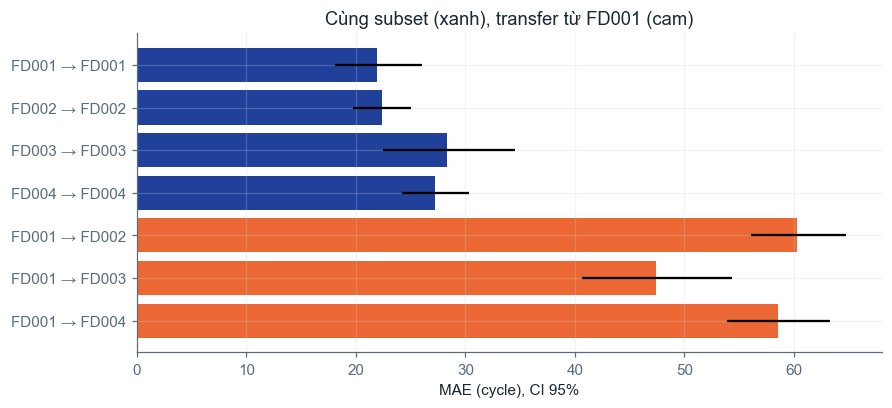

,mean_engine_mae,within_mae,ratio
target,,,
FD002,60.32,22.36,2.70
FD003,47.39,28.33,1.67
FD004,58.57,27.22,2.15


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
colors = np.where(cross.type.eq("transfer"), COLORS["orange"], COLORS["blue"])
ax.barh(cross.source + " → " + cross.target, cross.mean_engine_mae, color=colors,
        xerr=[cross.mean_engine_mae - cross.ci_lower, cross.ci_upper - cross.mean_engine_mae])
ax.invert_yaxis()
ax.set(xlabel="MAE (cycle), CI 95%", title="Cùng subset (xanh), transfer từ FD001 (cam)")
style_figure(fig)
fig.savefig(OUTPUT / "figures/cross_dataset.png", dpi=150)
style_figure(plt.gcf())
plt.show()
transfer[["mean_engine_mae", "within_mae", "ratio"]].round(2)

Transfer làm MAE tăng khoảng 1,7 lần ở FD003 và 2,7 lần ở FD002.
CI hai cách đánh giá không chồng lấn ở cả ba subset trong các kết quả đã đo.

FD002 và FD004 có sáu điều kiện vận hành, còn FD001 và FD003 có một.
Đây là cơ sở để thử chuẩn hóa theo điều kiện vận hành ở phần 4; phép so sánh này chưa tách riêng
tác động của điều kiện vận hành và dạng lỗi.

## 2. So sánh cấu hình phải giữ nguyên động cơ và cycle

Nghiên cứu FD001 dùng 5 fold ngoài để đánh giá; trong mỗi fold ngoài, 3 fold trong chọn window,
tham số HGB và trọng số mẫu. Mọi phương án được chấm trên cùng cycle từ 30 trở đi.
Động cơ thuộc fold ngoài không được tham gia cả fit lẫn chọn cấu hình của lượt đó.

Đọc `outer_predictions.parquet` của run `20260928_rebuild`. Trước khi so sánh,
kiểm tra baseline và candidate có cùng khóa observations.

In [6]:
from cmapss.project import IMPROVEMENT_RUN
from cmapss.modeling.improvement.analysis import engine_metrics, paired_comparison

RUN = ROOT / IMPROVEMENT_RUN
outer = pd.read_parquet(RUN / "outer_predictions.parquet")
keys = ["split", "engine_id", "cycle"]
baseline_pred = outer.loc[outer.stage.eq("baseline")].sort_values(keys)
candidate_pred = outer.loc[outer.stage.eq("weights")].sort_values(keys)
pd.testing.assert_frame_equal(baseline_pred[keys].reset_index(drop=True),
                              candidate_pred[keys].reset_index(drop=True))
engine_tables = {stage: engine_metrics(frame) for stage, frame in outer.groupby("stage")}

Mỗi động cơ tạo một cặp MAE. Ví dụ động cơ train 1 có MAE baseline khoảng 20,18 và candidate khoảng 19,62:
giảm khoảng 0,56 cycle trên động cơ này. Chênh lệch được định nghĩa **candidate − baseline**,
nên số âm là tốt hơn.

In [7]:
baseline = engine_tables["baseline"]
candidate = engine_tables["weights"]
example = pd.DataFrame({"baseline": baseline.loc[1], "candidate": candidate.loc[1]})
example["delta"] = example.candidate - example.baseline
example.round(4)

,baseline,candidate,delta
mean_engine_mae,20.1776,19.6226,-0.5550
low_rul_engine_mae,2.1478,2.4517,0.3039
late_or_missed_rate,0.0000,0.0000,0.0000
early_alarm_burden,0.0000,0.0076,0.0076


Tính trên cả 100 động cơ ở từng giai đoạn để kiểm tra ví dụ vừa xem có phản ánh kết quả chung không.

In [8]:
ablation = pd.DataFrame({stage: table.mean() for stage, table in engine_tables.items()}).T
ablation["late_or_missed_count"] = [
    int(engine_tables[stage].late_or_missed_rate.sum()) for stage in ablation.index
]
ablation = ablation.reindex(["baseline", "windows", "parameters", "weights"])
ablation[["mean_engine_mae", "low_rul_engine_mae", "late_or_missed_count", "early_alarm_burden"]]

,mean_engine_mae,low_rul_engine_mae,late_or_missed_count,early_alarm_burden
baseline,20.214341,3.667627,49,0.012933
windows,20.214341,3.667627,49,0.012933
parameters,20.245890,3.672997,53,0.012580
weights,20.245890,3.672997,53,0.012580


Bước chọn window giữ window 30, nên dòng `windows` trùng với baseline.
Sau bước chọn tham số HGB, MAE tăng từ 20,21 lên 20,25 cycle; số động cơ bị cảnh báo trễ hoặc bỏ lỡ
tăng từ 49 lên 53. Bước chọn trọng số mẫu không làm kết quả thay đổi thêm.
Biểu đồ dưới đối chiếu chênh lệch với khoảng tin cậy để đánh giá mức cải thiện.

## 3. Áp dụng tiêu chí đã chốt trước khi xem test

Theo [kế hoạch nghiên cứu](../docs/plans/completed/2026-09-26-rul-model-improvement.md),
ưu tiên giảm MAE khi RUL ≤ 30 và tỷ lệ cảnh báo trễ/bỏ lỡ. Các chỉ số kiểm soát gồm
MAE toàn bộ và tỷ lệ thời gian báo sớm ở vùng RUL > 30; chúng không được tăng.

Tính CI bằng cách lấy mẫu lại **các cặp động cơ đã ghép**, 10.000 lần, seed 42.
Cách này giữ nguyên mối tương ứng baseline–candidate trong mỗi lần lấy mẫu.

In [9]:
final = paired_comparison(baseline, candidate, resamples=10000, seed=42).set_index("metric")
recorded = pd.read_csv(RUN / "paired_comparison.csv")
recorded = recorded.loc[recorded.stage.eq("weights")].set_index("metric")
columns = ["baseline", "candidate", "delta", "ci_lower", "ci_upper"]
np.testing.assert_allclose(final[columns], recorded.loc[final.index, columns], atol=1e-12)
final[columns]

,baseline,candidate,delta,ci_lower,ci_upper
metric,,,,,
mean_engine_mae,20.214341,20.245890,0.031549,-0.111240,0.173732
low_rul_engine_mae,3.667627,3.672997,0.005370,-0.050608,0.063884
late_or_missed_rate,0.490000,0.530000,0.040000,0.010000,0.080000
early_alarm_burden,0.012933,0.012580,-0.000353,-0.001320,0.000627


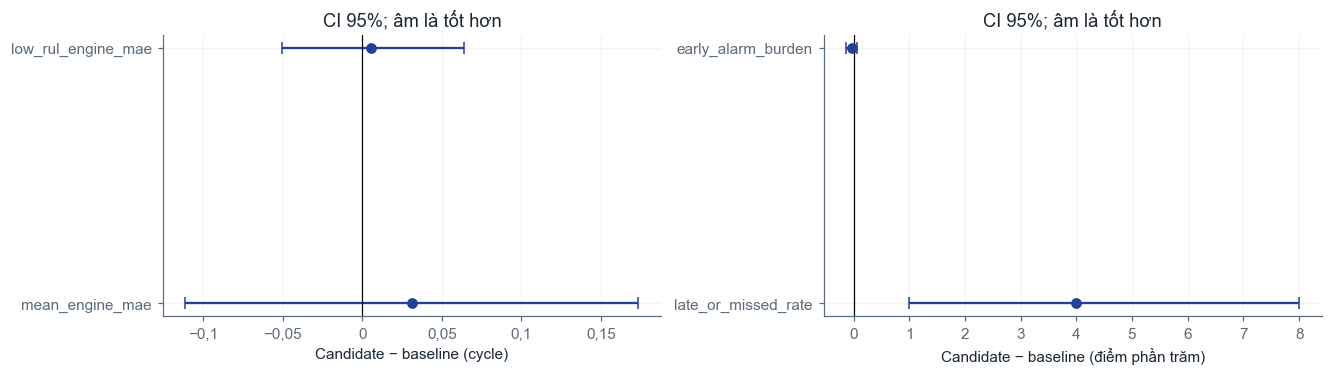

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), layout="constrained")
metric_groups = [["mean_engine_mae", "low_rul_engine_mae"],
                 ["late_or_missed_rate", "early_alarm_burden"]]
for ax, names, scale, unit in zip(axes, metric_groups, [1, 100], ["cycle", "điểm phần trăm"]):
    values = final.loc[names, ["delta", "ci_lower", "ci_upper"]] * scale
    ax.errorbar(values.delta, names,
                xerr=[values.delta - values.ci_lower, values.ci_upper - values.delta],
                fmt="o", capsize=4)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(xlabel=f"Candidate − baseline ({unit})", title="CI 95%; âm là tốt hơn")
style_figure(fig)
fig.savefig(OUTPUT / "figures/paired_comparison.png", dpi=150)
style_figure(plt.gcf())
plt.show()

MAE toàn bộ tăng 0,03 cycle; MAE vùng RUL ≤ 30 tăng 0,005 cycle, với CI còn chứa 0.
Tỷ lệ cảnh báo trễ/bỏ lỡ tăng từ 0,49 lên 0,53; CI chênh lệch 0,01–0,08 nằm trên 0.
Kết quả không đạt tiêu chí cải thiện.

Cell dưới kiểm tra riêng mức thay đổi quan sát được, CI của hai chỉ số ưu tiên và quyết định đã lưu.
CI này điều kiện trên dự đoán đã fit, chưa bao gồm biến động khi huấn luyện lại.

In [11]:
priority = ["low_rul_engine_mae", "late_or_missed_rate"]
controls = ["mean_engine_mae", "late_or_missed_rate", "early_alarm_burden"]
observed_improvement = bool((final.loc[priority, "delta"] < 0).all()
                            and (final.loc[controls, "delta"] <= 0).all())
intervals_below_zero = bool((final.loc[priority, "ci_upper"] < 0).all())
decision = json.loads((RUN / "decision.json").read_text(encoding="utf-8"))
assert observed_improvement == decision["observed_improvement_meets_plan"]
assert intervals_below_zero == decision["both_primary_intervals_below_zero"]
pd.Series({"observed_improvement": observed_improvement,
           "priority_CIs_below_zero": intervals_below_zero,
           "default_model": decision["default_model"]})

observed_improvement                 False
priority_CIs_below_zero              False
default_model              retain_baseline
dtype: object

Khi chọn lại cấu hình bằng toàn bộ train, run vẫn chọn window 30, trọng số đều,
learning rate 0,05 và 200 vòng lặp. Bảng test dưới đây là kết quả đã lưu sau khi chọn,
được trình bày để đối chiếu, không dùng thay quyết định từ outer evaluation.

In [12]:
run_info = json.loads((RUN / "run_info.json").read_text(encoding="utf-8"))
display(pd.Series(run_info["selected_final"], name="cấu hình cuối"))
pd.read_csv(RUN / "test_comparison.csv")[
    ["model", "mean_engine_mae", "rmse", "nasa_score", "low_rul_engine_mae"]
]

window                    30
weight_scheme        uniform
learning_rate           0.05
max_iter                 200
max_leaf_nodes            31
min_samples_leaf          20
l2_regularization        0.0
Name: cấu hình cuối, dtype: object

,model,mean_engine_mae,rmse,nasa_score,low_rul_engine_mae
0,baseline,15.349047,20.541267,1513.257656,4.383042
1,selected_final,15.349047,20.541267,1513.257656,4.383042


Khi chọn cấu hình trên toàn bộ train, kết quả cuối là window 30, trọng số đều, learning rate 0,05
và 200 vòng lặp. Cấu hình này cho kết quả test trùng với baseline: MAE 15,35 cycle, RMSE 20,54.

## 4. Đọc thí nghiệm bổ sung ngày 29/09/2026 theo cùng nguyên tắc

FD001 thử cap RUL ở 110, 125, 140 hoặc không cap, cùng 42 features lịch sử.
FD002 và FD004 thử thêm settings và chuẩn hóa theo sáu điều kiện vận hành;
bộ chuẩn hóa chỉ học từ phần train của fold. Cấu hình dùng 3 fold trong và 5 fold ngoài.

Gate của FD001 yêu cầu CI giảm ở MAE RUL thấp và cảnh báo trễ, đồng thời kiểm soát MAE toàn bộ
và alarm burden. Gate của FD002/FD004 xét CI của MAE toàn bộ. Cần đọc đúng gate của từng nghiên cứu.

Test đã được xem trong nghiên cứu trước, nên kết quả test bổ sung chỉ mang tính khám phá.
MAE test thấp hơn không thay thế được tiêu chí outer evaluation.

In [13]:
from cmapss.followup_results import load_followup_results

followup, paired_followup = load_followup_results(ROOT)
followup[["dataset", "selected_final", "n_features", "outer_gate_passed"]]

,dataset,selected_final,n_features,outer_gate_passed
0,FD001,cap_none_history_1,168,False
1,FD002,condition_normalized,132,True
2,FD004,condition_normalized,132,True


Tách kết quả vòng ngoài thành sai số và cảnh báo, để tránh một bảng quá rộng.

In [14]:
followup[["dataset", "baseline_outer_mae", "selected_outer_mae",
          "baseline_low_mae", "selected_low_mae", "baseline_late", "selected_late"]]

,dataset,baseline_outer_mae,selected_outer_mae,baseline_low_mae,selected_low_mae,baseline_late,selected_late
0,FD001,20.214341,20.296600,3.667627,3.217124,49,55
1,FD002,29.286082,28.039007,8.712689,6.484867,147,153
2,FD004,36.742791,35.449094,9.117203,7.171386,139,140


In [15]:
paired_followup[["dataset", "metric", "delta", "ci_lower", "ci_upper"]]

,dataset,metric,delta,ci_lower,ci_upper
0,FD001,mean_engine_mae,0.082259,-1.068041,1.156333
1,FD001,low_rul_engine_mae,-0.450503,-0.694039,-0.225656
2,FD001,late_or_missed_rate,0.060000,-0.020000,0.140000
3,FD001,early_alarm_burden,-0.002853,-0.005203,-0.000755
4,FD002,mean_engine_mae,-1.247075,-1.664977,-0.814142
5,FD002,low_rul_engine_mae,-2.227822,-2.649687,-1.829226
6,FD002,late_or_missed_rate,0.023077,-0.026923,0.073077
7,FD002,early_alarm_burden,-0.003162,-0.005305,-0.001077
8,FD004,mean_engine_mae,-1.293697,-1.886829,-0.683630
9,FD004,low_rul_engine_mae,-1.945817,-2.383676,-1.474536


Sau cùng mới xem test và NASA score. NASA score phạt mạnh các ca dự đoán RUL quá cao,
nên giảm MAE chưa chắc giảm chỉ số này.

In [16]:
followup[["dataset", "historical_test_mae", "test_mae",
          "historical_test_nasa_score", "test_nasa_score"]]

,dataset,historical_test_mae,test_mae,historical_test_nasa_score,test_nasa_score
0,FD001,15.349047,13.046016,1513.257656,2.605280e+03
1,FD002,22.355599,19.179681,34004.978222,1.750118e+04
2,FD004,27.221778,26.612340,492703.070867,1.205603e+06


In [17]:
followup[["dataset", "test_rmse", "baseline_outer_rmse", "selected_outer_rmse",
          "baseline_outer_nasa", "selected_outer_nasa"]]

,dataset,test_rmse,baseline_outer_rmse,selected_outer_rmse,baseline_outer_nasa,selected_outer_nasa
0,FD001,19.313266,33.635902,36.810376,1.884981e+08,2.589672e+08
1,FD002,27.495428,42.548843,41.319330,6.859922e+08,4.573348e+08
2,FD004,36.745214,56.595046,55.651587,6.205627e+12,1.346413e+13


Ở FD001, cấu hình được chọn là `cap_none_history_1`: không cap RUL và có thêm đặc trưng lịch sử.
MAE vòng ngoài thay đổi từ 20,21 lên 20,30, với khoảng tin cậy của chênh lệch từ −1,07 đến 1,16.
Cấu hình không đạt tiêu chí dù MAE vùng RUL thấp giảm 0,45 cycle.
MAE test là 13,05, thấp hơn 15,35 của baseline. Do test đã được xem trước, kết quả này không được dùng
để quyết định thay mô hình.

Chuẩn hóa theo điều kiện vận hành ở FD002 và FD004 đạt tiêu chí vòng ngoài: MAE giảm lần lượt 1,25
và 1,29 cycle; MAE vùng RUL thấp giảm khoảng 2 cycle, với các khoảng tin cậy đều dưới 0.
Trên test, MAE FD002 giảm từ 22,36 xuống 19,18; FD004 từ 27,22 xuống 26,61 so với kết quả nội bộ ở phần 1.

NASA score, chỉ số phạt mạnh dự đoán trễ, lại tăng ở FD001 và FD004 trên cả vòng ngoài lẫn test.
Tỷ lệ cảnh báo trễ không giảm ở subset nào. Mức giảm MAE chưa đi kèm cải thiện ở các ca dự đoán RUL quá cao.

## 5. Lưu phép tính đã kiểm tra

Lưu metric tính lại và đường dẫn hai nguồn thí nghiệm, để phân biệt với một lượt huấn luyện mới.

In [18]:
import hashlib

cross.to_csv(OUTPUT / "cross_metrics.csv", index=False)
ablation.to_csv(OUTPUT / "ablation_metrics.csv")
final.to_csv(OUTPUT / "paired_comparison.csv")
followup.to_csv(OUTPUT / "followup_summary.csv", index=False)
sources = [CROSS / "matrix.json", RUN / "outer_predictions.parquet", RUN / "decision.json"]
provenance = {
    "author": "Phan Nguyễn Mai Phương", "student_id": "25002711", "refit_models": False,
    "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in sources},
    "paired_bootstrap_resamples": 10000, "seed": 42,
}
(OUTPUT / "run_info.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook05\run-k27bgocp


động cơ train 1 cải thiện không có nghĩa cả quy trình đã tốt hơn: cần giữ nguyên khóa đánh giá,
tổng hợp trên mọi động cơ và áp dụng tiêu chí đã chốt. Nghiên cứu FD001 giữ baseline;
thí nghiệm chuẩn hóa theo điều kiện vận hành cho FD002/FD004 có bằng chứng giảm MAE,
nhưng vẫn cần xem NASA score và cảnh báo trước khi quyết định ứng dụng.